<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h1 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 34px;
    ">
        Rice Variety Classification Using CNN (TensorFlow & Keras)
    </h1>
</div>


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Welcome! 👋
        <br>
        <br>
        Hello, everyone!
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Welcome to this project. Let's explore the data and uncover
        interesting insights together!
    </p>
</div>


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Project Overview
</h3>

<p>
This project aims to develop a deep learning model for rice variety classification using image data. A Convolutional Neural Network (CNN) is implemented to identify five rice varieties through visual analysis.

The project follows a structured workflow, from data preparation and model development to training, experimentation, and performance evaluation, with a focus on understanding CNN architecture and improving classification performance.
</p>
</div>

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Why This Dataset?
</h3>

<p>
    The Rice Image Dataset was selected to investigate the effectiveness of deep learning in distinguishing visually similar rice varieties. The dataset contains 75,000 images belonging to five classes: Arborio, Basmati, Ipsala, Jasmine, and Karacadag.

The classification task requires the model to learn discriminative visual features, including grain shape, texture, and color. The dataset also provides sufficient samples to develop, train, and evaluate a multiclass image classification model.
</p>

<hr style="border: 0; border-top: 5px solid #D9AA55;">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Why Convolutional Neural Networks (CNNs)?
</h3>

<p>
    Convolutional Neural Networks (CNNs) were selected because they are specifically designed to process grid-structured data such as images.

Unlike traditional fully connected neural networks, CNNs use convolutional filters to learn spatial patterns while sharing parameters across different image regions.

In rice image classification, these filters can capture visual characteristics such as edges, grain shapes, and textures. As information passes through deeper layers, the network can learn increasingly complex representations that help distinguish between rice varieties.

Additionally, CNNs reduce the need for manual feature engineering by automatically learning relevant visual features directly from training images.

The objective of this project is to investigate how effectively a CNN can classify five rice varieties using TensorFlow and Keras.
</p>

</div>



<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Importing libraries
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Importing the essential libraries for data processing,
        visualization, and deep learning.
    </p>
</div>


In [1]:
# ==================== Standard Python Libraries ====================
import os
import time
import random
from pathlib import Path

# ==================== Data Manipulation & Numerical Computing ====================
import numpy as np
import pandas as pd

# ==================== Data Visualization ====================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ==================== Data Splitting & Machine Learning Utilities ====================
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ==================== Image Processing ====================
import cv2
from PIL import Image
from skimage.io import imread

# ==================== Deep Learning Framework - TensorFlow & Keras ====================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, Input, Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# ==================== Data Augmentation & Preprocessing ====================
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ==================== Optimization & Loss Functions ====================
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy


print("All required libraries imported successfully.")

All required libraries imported successfully.


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Reading Data
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Loading the dataset for analysis
    </p>
</div>


In [ ]:
dataset_path = Path("/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset")

CLASS_NAMES = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg")

In [3]:
def load_image_paths(directory: Path):
    image_paths = []
    
    if not directory.is_dir():
        raise FileNotFoundError(f"Directory not found: {directory}")

    for filename in os.listdir(directory):
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            image_path = directory / filename
            if image_path.is_file():
                image_paths.append(str(image_path))

    return sorted(image_paths)

In [4]:
image_list_arborio = load_image_paths(dataset_path / "Arborio")

image_list_basmati = load_image_paths(dataset_path / "Basmati")

image_list_ipsala = load_image_paths(dataset_path / "Ipsala")

image_list_jasmine = load_image_paths(dataset_path / "Jasmine")

image_list_karacadag = load_image_paths(dataset_path / "Karacadag")

In [5]:
image_lists = {
    "Arborio": image_list_arborio,
    "Basmati": image_list_basmati,
    "Ipsala": image_list_ipsala,
    "Jasmine": image_list_jasmine,
    "Karacadag": image_list_karacadag
}

class_distribution = pd.DataFrame({
    "Class": list(image_lists.keys()),
    "Count": [len(paths) for paths in image_lists.values()]
})

display(class_distribution)

print(f"Total Images: {class_distribution['Count'].sum():,}")

,Class,Count
0,Arborio,15000
1,Basmati,15000
2,Ipsala,15000
3,Jasmine,15000
4,Karacadag,15000


Total Images: 75,000


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        PreProcessing
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Preparing images for model training
    </p>
</div>


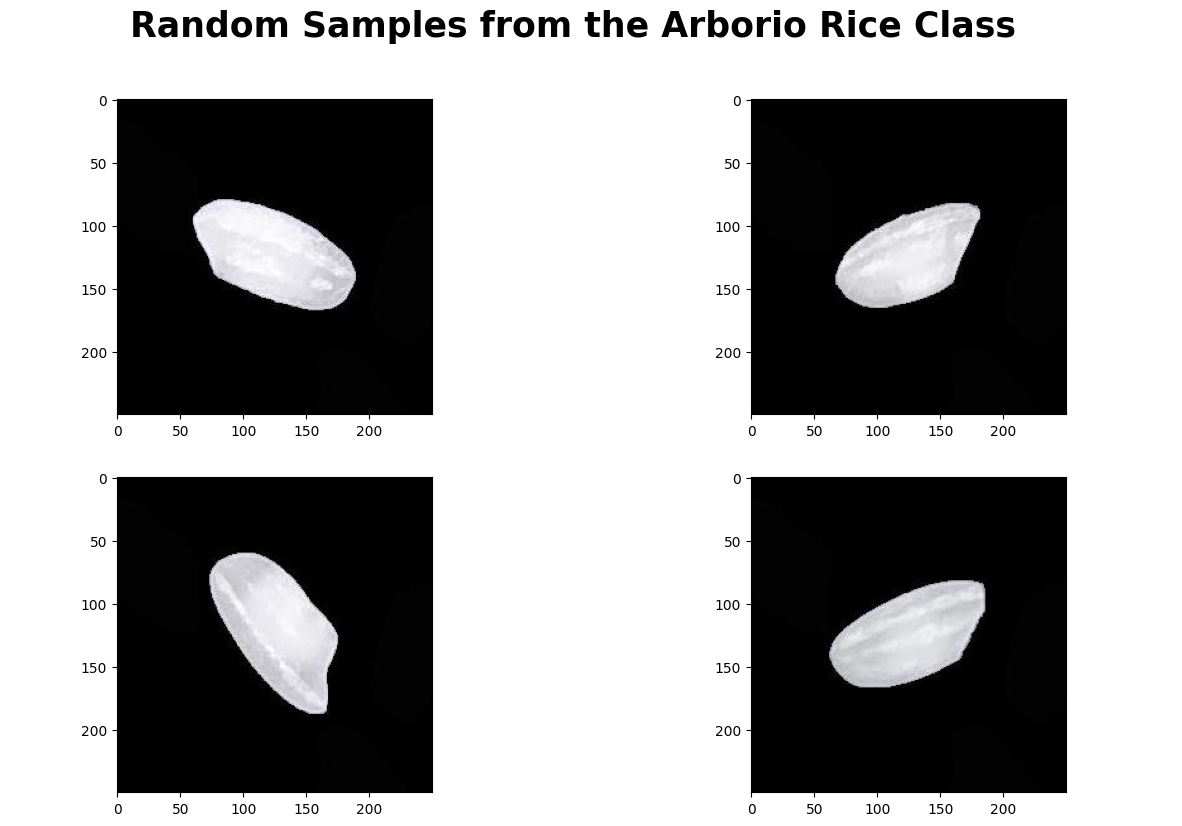

In [6]:
plt.figure(1, figsize=(15, 9))
plt.axis('off')
n = 0
for i in range(4):
    
    n += 1
    random_img = random.choice(image_list_arborio)
    imgs = imread(random_img)
    plt.suptitle("Random Samples from the Arborio Rice Class", fontsize=25, fontweight="bold")
    plt.subplot(2,2,n)
    plt.imshow(imgs)

plt.show()

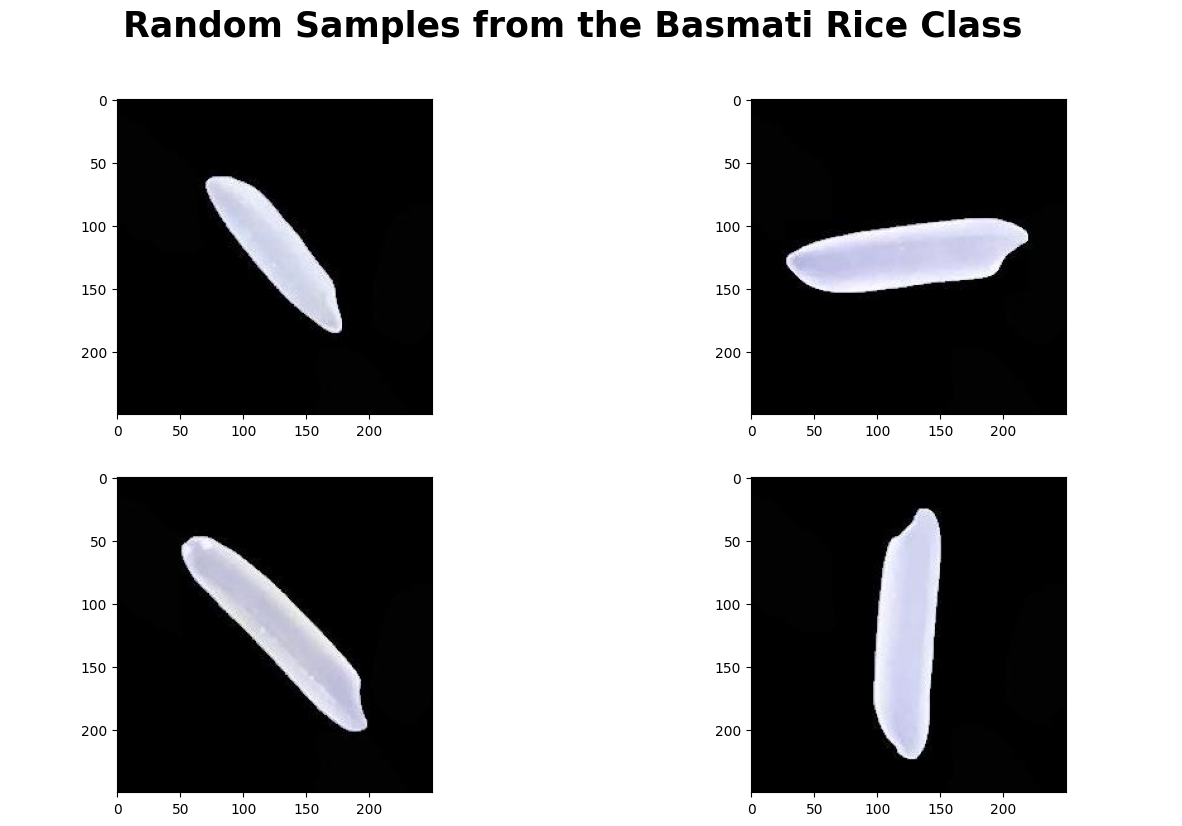

In [7]:
plt.figure(1, figsize=(15, 9))
plt.axis('off')
n = 0
for i in range(4):
    
    n += 1
    random_img = random.choice(image_list_basmati)
    imgs = imread(random_img)
    plt.suptitle("Random Samples from the Basmati Rice Class", fontsize=25, fontweight="bold")
    plt.subplot(2,2,n)
    plt.imshow(imgs)

plt.show()

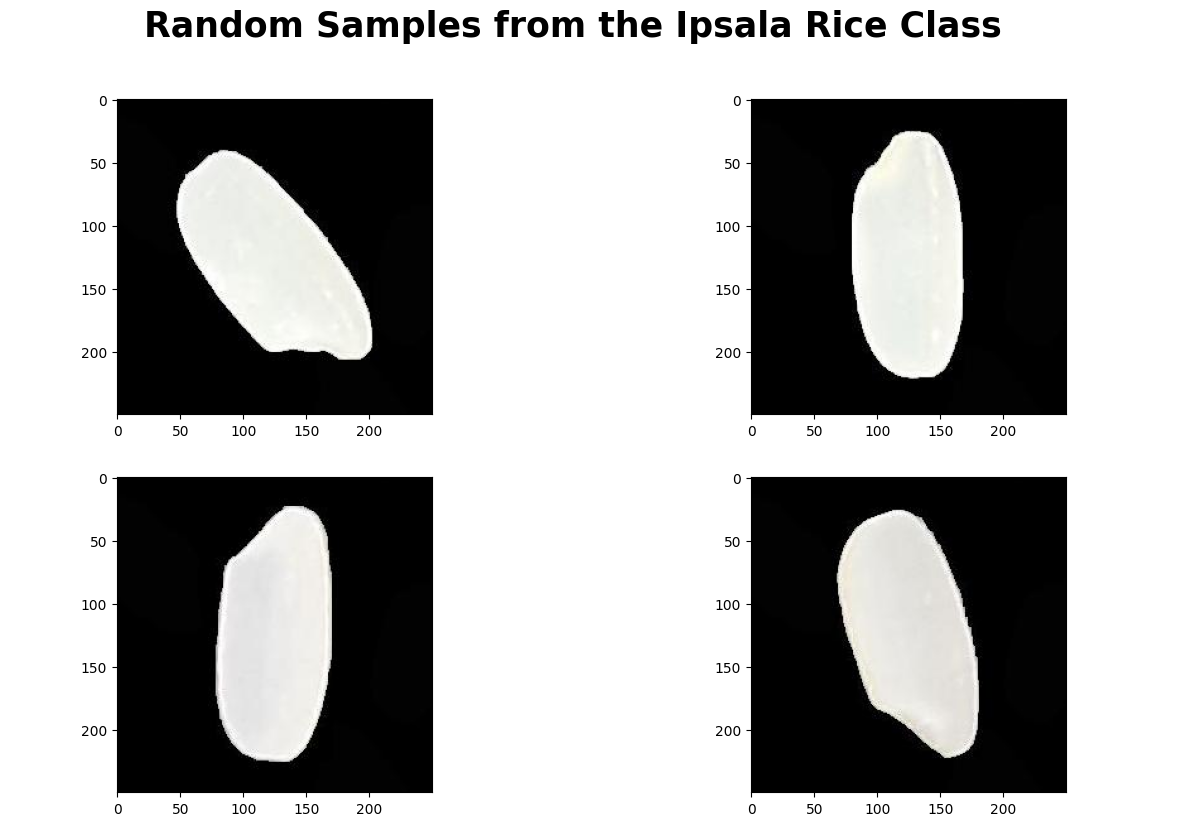

In [8]:
plt.figure(1, figsize=(15, 9))
plt.axis('off')
n = 0
for i in range(4):
    
    n += 1
    random_img = random.choice(image_list_ipsala)
    imgs = imread(random_img)
    plt.suptitle("Random Samples from the Ipsala Rice Class", fontsize=25, fontweight="bold")
    plt.subplot(2,2,n)
    plt.imshow(imgs)

plt.show()

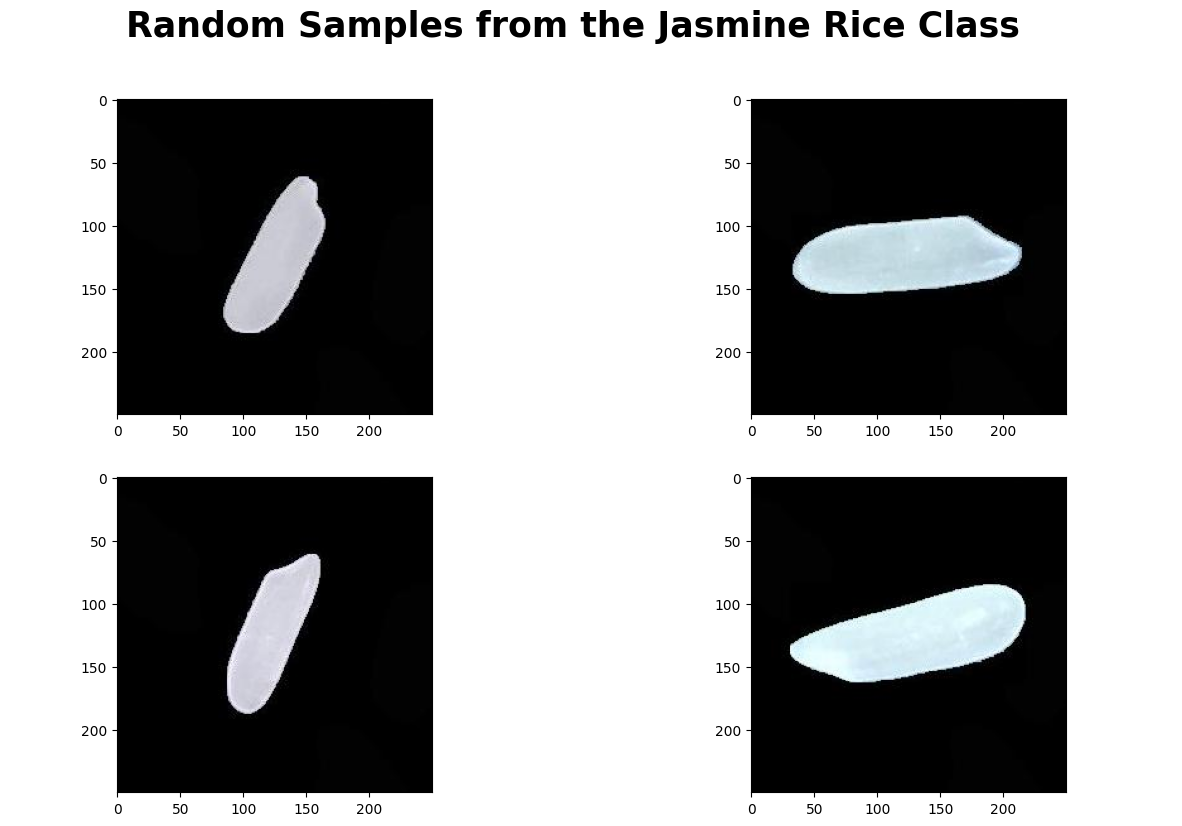

In [9]:
plt.figure(1, figsize=(15, 9))
plt.axis('off')
n = 0
for i in range(4):
    
    n += 1
    random_img = random.choice(image_list_jasmine)
    imgs = imread(random_img)
    plt.suptitle("Random Samples from the Jasmine Rice Class", fontsize=25, fontweight="bold")
    plt.subplot(2,2,n)
    plt.imshow(imgs)

plt.show()

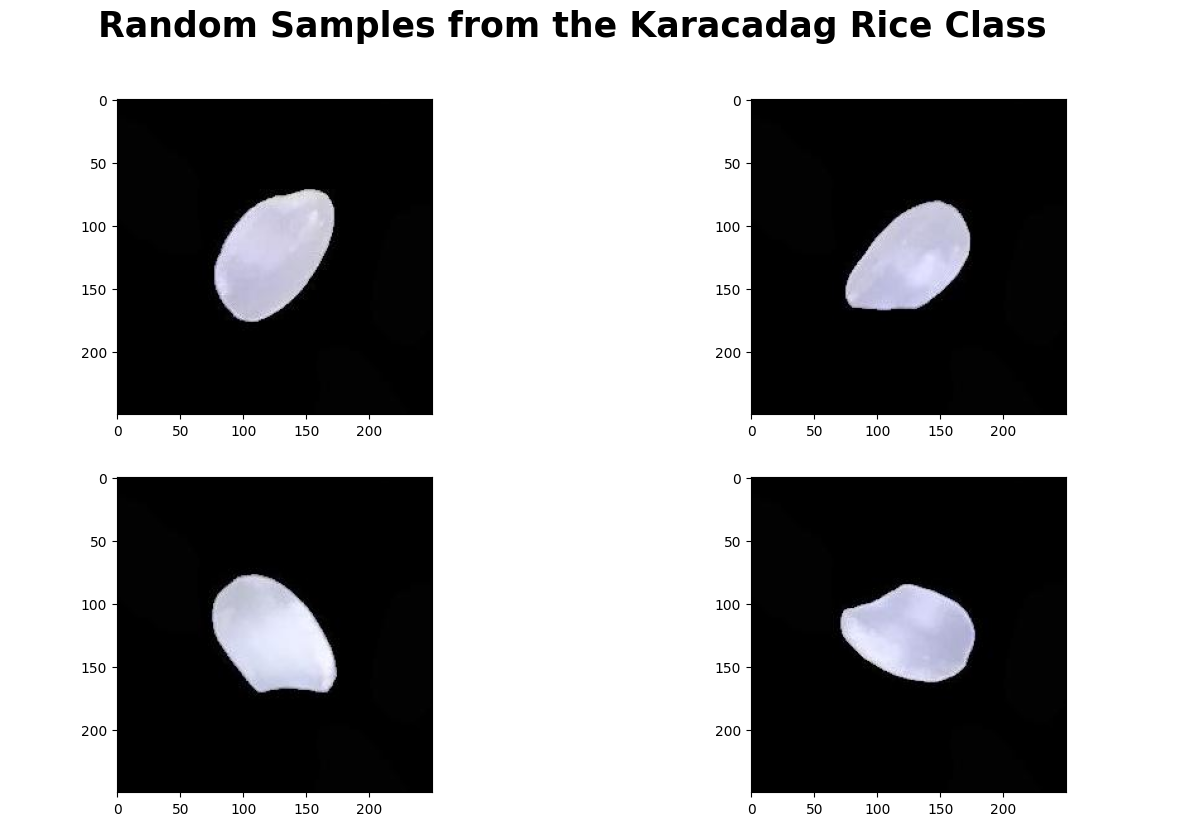

In [10]:
plt.figure(1, figsize=(15, 9))
plt.axis('off')
n = 0
for i in range(4):
    
    n += 1
    random_img = random.choice(image_list_karacadag)
    imgs = imread(random_img)
    plt.suptitle("Random Samples from the Karacadag Rice Class", fontsize=25, fontweight="bold")
    plt.subplot(2,2,n)
    plt.imshow(imgs)

plt.show()

In [11]:
print("Number of samples in (Class = Arborio) = " ,len(image_list_arborio))
print("Number of samples in (Class = Basmati) = " ,len(image_list_basmati))
print("Number of samples in (Class = Ipsala) = " ,len(image_list_ipsala))
print("Number of samples in (Class = Jasmine) = " ,len(image_list_jasmine))
print("Number of samples in (Class = Karacadag) = " ,len(image_list_karacadag))

Number of samples in (Class = Arborio) =  15000
Number of samples in (Class = Basmati) =  15000
Number of samples in (Class = Ipsala) =  15000
Number of samples in (Class = Jasmine) =  15000
Number of samples in (Class = Karacadag) =  15000


In [12]:
def train_test_val_split(image_lists, test_size=0.15, val_size=0.15, seed=42):
    records = [
        {"image": path, "label": cls}
        for cls, paths in image_lists.items()
        for path in paths
    ]
    df = pd.DataFrame(records)

    train_val, test = train_test_split(
        df, test_size=test_size, stratify=df["label"], random_state=seed
    )
    train, val = train_test_split(
        train_val,
        test_size=val_size / (1 - test_size),
        stratify=train_val["label"],
        random_state=seed,
    )

    return (
        train.sample(frac=1, random_state=seed).reset_index(drop=True),
        val.reset_index(drop=True),
        test.reset_index(drop=True),
    )

In [13]:
train_df, val_df, test_df = train_test_val_split(image_lists)

In [14]:
print("Number of rows in train dataframe is: ", len(train_df))
print("Number of rows in test dataframe is: ", len(test_df))
print("Number of rows in val dataframe is: ", len(val_df))

Number of rows in train dataframe is:  52500
Number of rows in test dataframe is:  11250
Number of rows in val dataframe is:  11250


In [15]:
print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Validation:", val_df.shape)

Train: (52500, 2)
Test: (11250, 2)
Validation: (11250, 2)


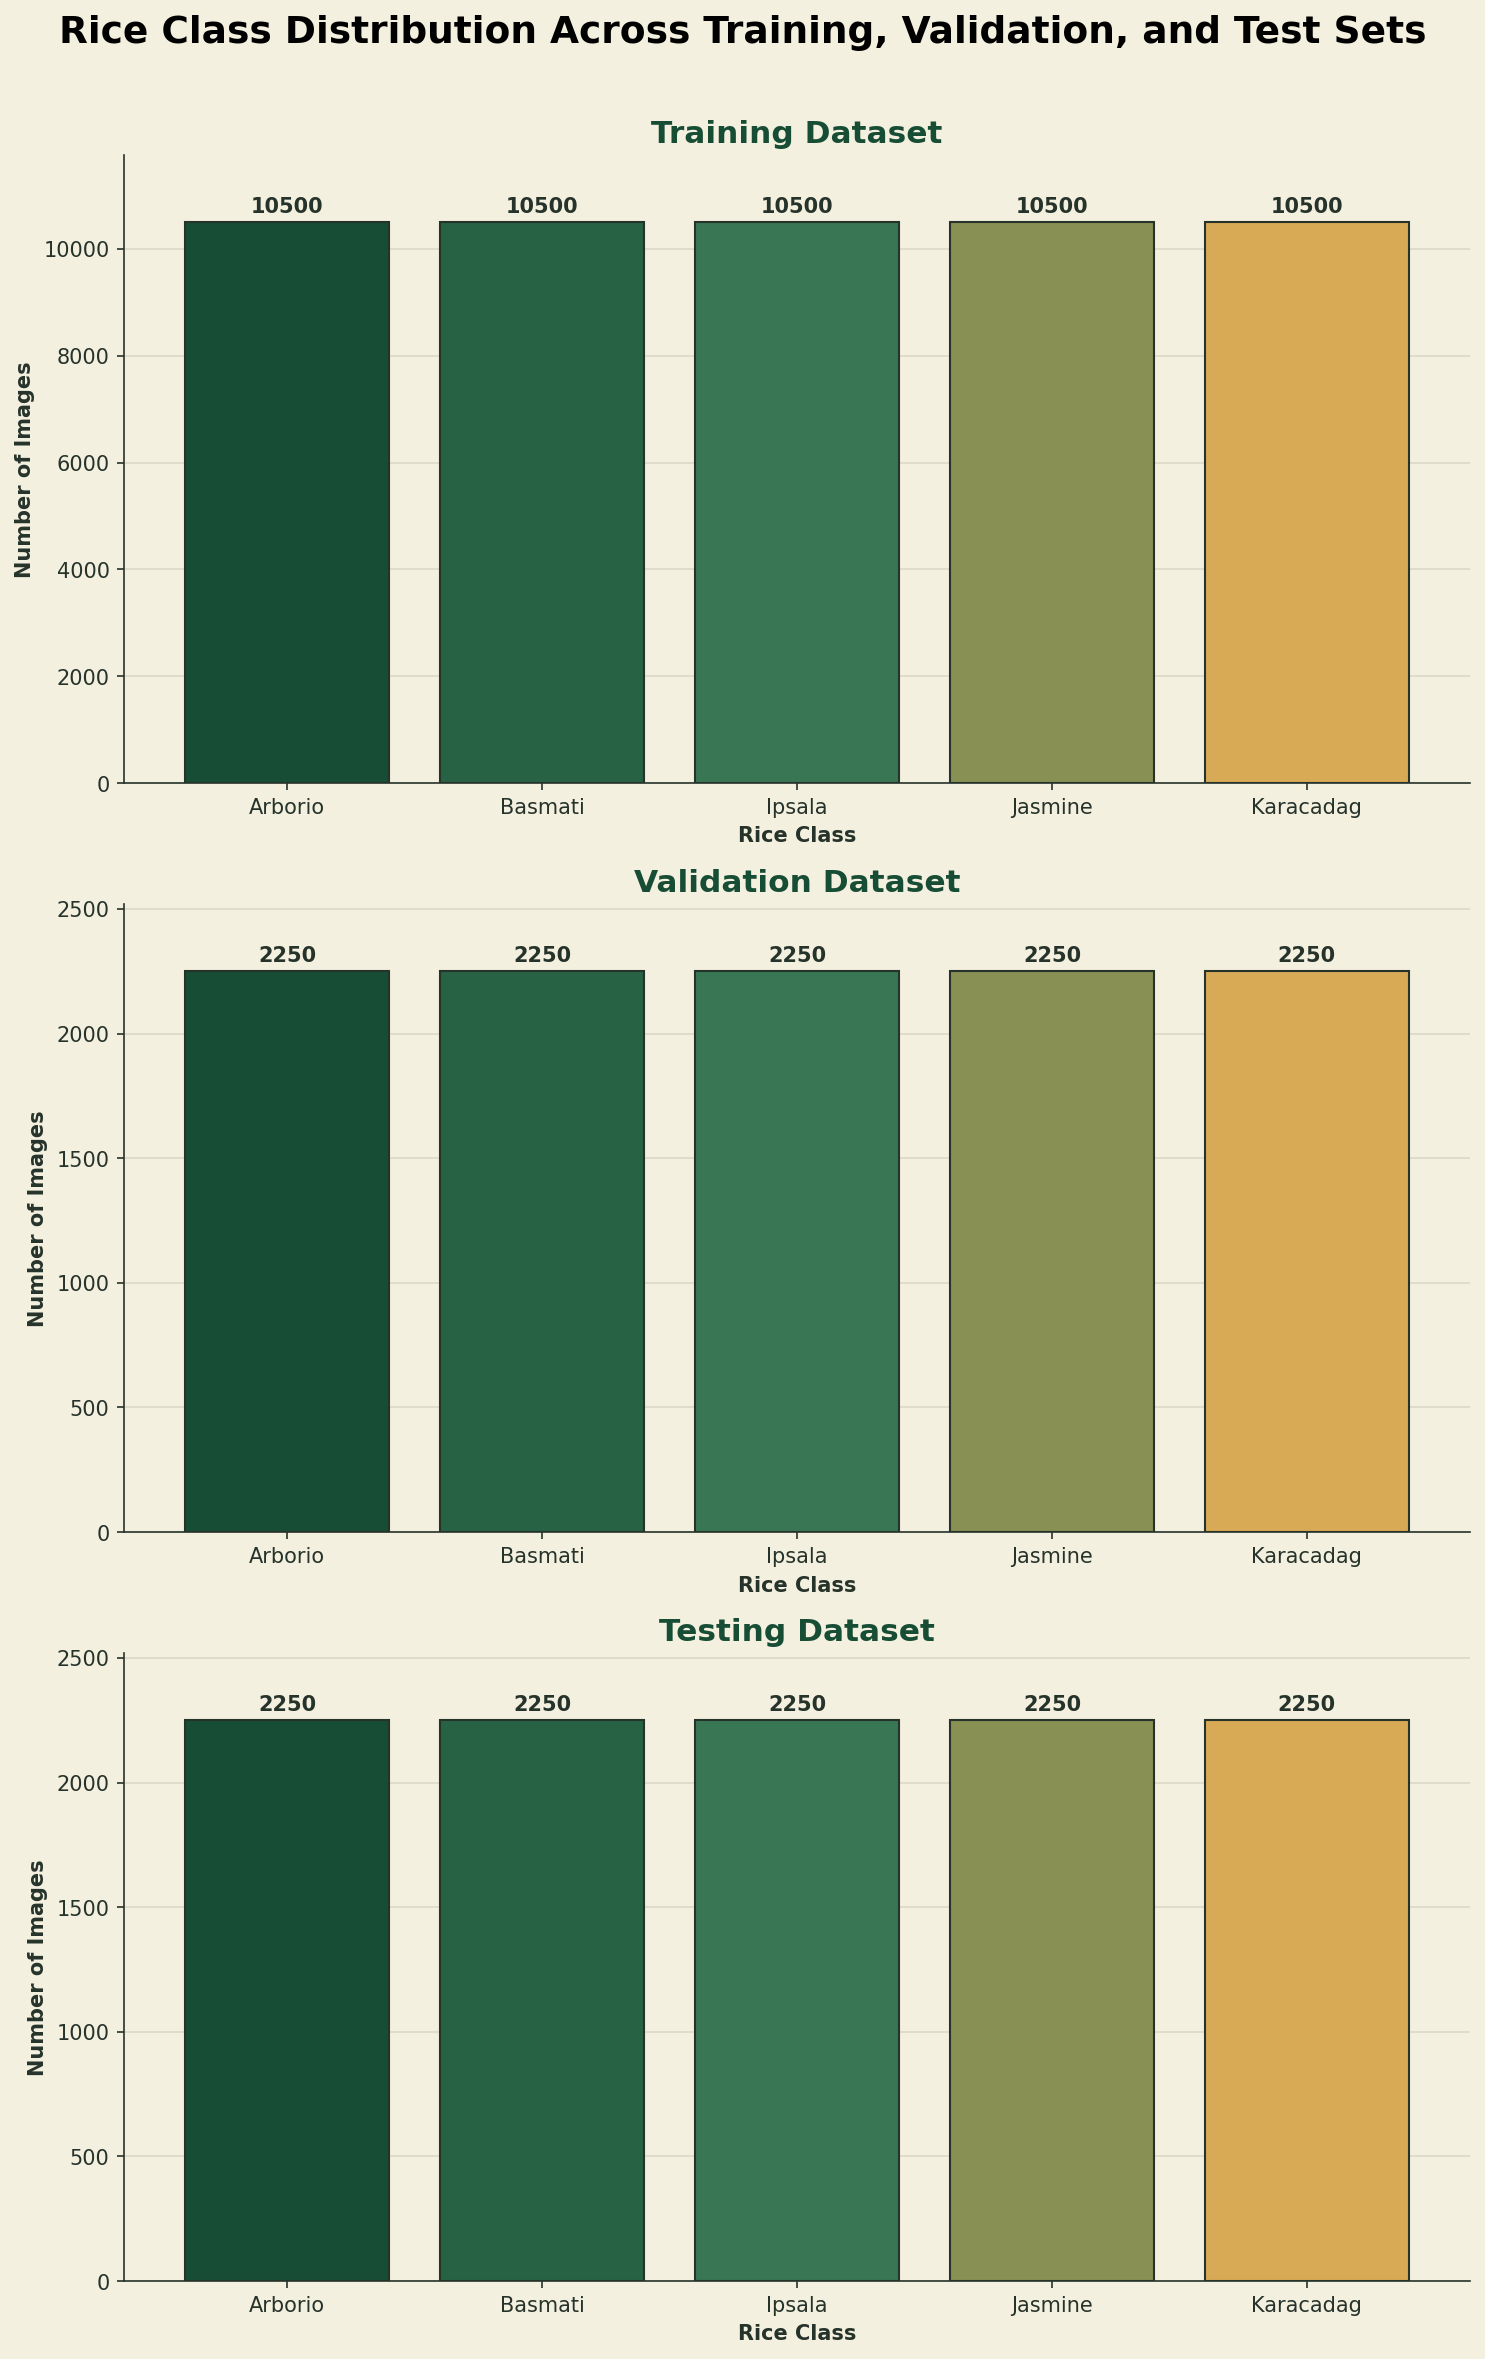

In [16]:
DARK_GREEN = "#174D35"   
GREEN      = "#387653"   
GOLD       = "#D9AA55"  
CREAM      = "#F4F0DF"   
TEXT       = "#26332B"   

cmap = LinearSegmentedColormap.from_list("rice", [DARK_GREEN, GREEN, GOLD])
class_colors = [cmap(i / 4) for i in range(5)]

datasets = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

fig, axes = plt.subplots(3, 1, figsize=(10, 16), dpi=150, facecolor=CREAM)

for ax, (title, data) in zip(axes, datasets.items()):

    counts = data["label"].value_counts().sort_index()

    ax.set_facecolor(CREAM)

    bars = ax.bar(counts.index, counts.values, color=class_colors, edgecolor=TEXT, linewidth=1)

    ax.set_title(f"{title} Dataset", fontsize=15, fontweight="bold", color=DARK_GREEN)
    ax.set_xlabel("Rice Class", fontweight="bold", color=TEXT)
    ax.set_ylabel("Number of Images", fontweight="bold", color=TEXT)
    ax.tick_params(colors=TEXT)

    
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(TEXT)
    ax.yaxis.grid(True, color=TEXT, alpha=0.12)
    ax.set_axisbelow(True)

    ax.bar_label(bars, fmt="%d", padding=3, fontsize=10, fontweight="bold", color=TEXT)
    ax.set_ylim(0, counts.max() * 1.12)

fig.suptitle("Rice Class Distribution Across Training, Validation, and Test Sets", fontsize=18, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [17]:
train_df.head()

,image,label
0,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
1,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
2,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
3,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
4,/kaggle/input/datasets/muratkokludataset/rice-...,Basmati


In [18]:
random_img_path = random.choice(train_df["image"].tolist())

image= cv2.imread(random_img_path)

height, width= image.shape[:2]

print("The height is ", height)

print("The width is ", width)

The height is  250
The width is  250


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h2 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Image Color Space Analysis
</h2>
<p>
All images in our rice dataset have a black background, while the rice grains appear white. But are these images actually grayscale, or are they stored as RGB images?

In this step, we will examine the color space of the images to determine how their pixel values are represented and whether they contain color information.

This analysis will help us understand the image characteristics and choose an appropriate preprocessing approach for our CNN model.
</p>
</div>

In [19]:
random_img_path = random.choice(train_df["image"].tolist())

image = cv2.imread(random_img_path)

blue, green, red = cv2.split(image)

print("Image shape:", image.shape)

print("Blue == Green:", np.array_equal(blue, green))
print("Green == Red:", np.array_equal(green, red))
print("Blue == Red:", np.array_equal(blue, red))

Image shape: (250, 250, 3)
Blue == Green: False
Green == Red: False
Blue == Red: False


In [20]:
blue, green, red = cv2.split(image)

print("Mean B-G difference:",
      np.mean(np.abs(blue.astype(float) - green.astype(float))))

print("Mean G-R difference:",
      np.mean(np.abs(green.astype(float) - red.astype(float))))

print("Mean B-R difference:",
      np.mean(np.abs(blue.astype(float) - red.astype(float))))

Mean B-G difference: 2.016304
Mean G-R difference: 0.19232
Mean B-R difference: 1.831184


In [21]:
sample_size = 100
results = []

for class_name, group in train_df.groupby("label"):
    sampled_images = group.sample(n=min(sample_size, len(group)), random_state=42)

    differences = []

    for image_path in sampled_images["image"]:
        image = cv2.imread(image_path)
        if image is None:
            continue
        blue, green, red = cv2.split(image)

        blue = blue.astype(np.float32)
        green = green.astype(np.float32)
        red = red.astype(np.float32)

        differences.append({
            "B-G": np.mean(np.abs(blue - green)),
            "G-R": np.mean(np.abs(green - red)),
            "B-R": np.mean(np.abs(blue - red))
        })

    if not differences:
        continue

    class_results = pd.DataFrame(differences).mean()

    results.append({
        "Class": class_name,
        "Images": len(differences),
        "Mean B-G": class_results["B-G"],
        "Mean G-R": class_results["G-R"],
        "Mean B-R": class_results["B-R"]
    })

color_analysis_df = pd.DataFrame(results)

display(color_analysis_df.round(4))

,Class,Images,Mean B-G,Mean G-R,Mean B-R
0,Arborio,100,0.8389,0.1277,0.8576
1,Basmati,100,2.2877,0.4071,2.4856
2,Ipsala,100,0.9388,0.4043,0.9038
3,Jasmine,100,1.0074,0.8346,1.7579
4,Karacadag,100,2.2479,0.1909,2.2349


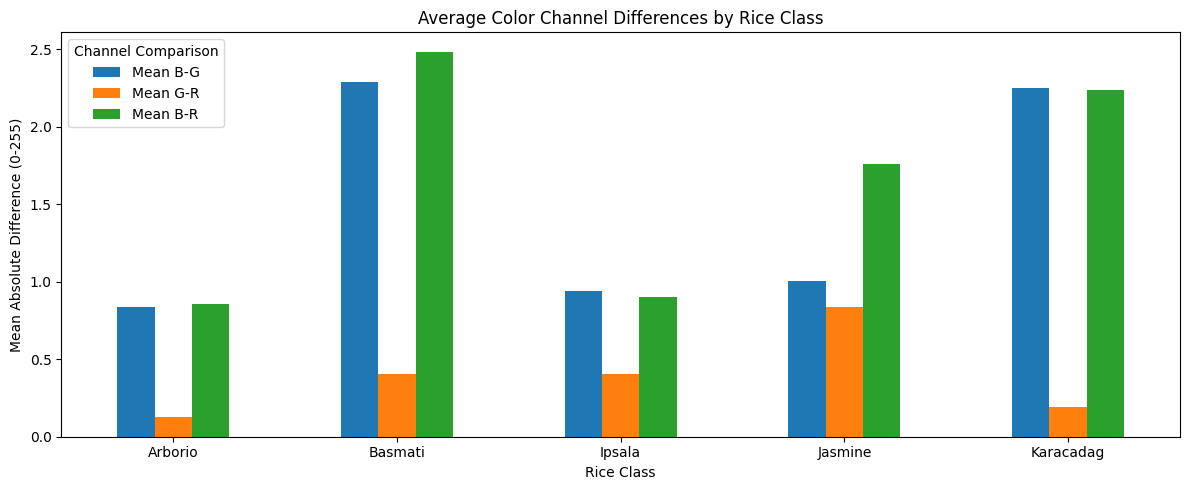

In [22]:
color_analysis_df.set_index("Class")[
    ["Mean B-G", "Mean G-R", "Mean B-R"]
].plot(kind="bar", figsize=(12, 5), rot=0)

plt.title("Average Color Channel Differences by Rice Class")
plt.xlabel("Rice Class")
plt.ylabel("Mean Absolute Difference (0-255)")
plt.legend(title="Channel Comparison")
plt.tight_layout()
plt.show()

In [23]:
results = []

for class_name, group in train_df.groupby("label"):
    sampled_images = group.sample(n=min(100, len(group)), random_state=42)
    for image_path in sampled_images["image"]:
        image = cv2.imread(image_path)
        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        mask = gray > 30
        if not np.any(mask):
            continue

        blue, green, red = cv2.split(image.astype(np.float32))

        results.append({
            "Class": class_name,
            "B-G": np.mean(np.abs(blue[mask] - green[mask])),
            "G-R": np.mean(np.abs(green[mask] - red[mask])),
            "B-R": np.mean(np.abs(blue[mask] - red[mask]))
        })

foreground_analysis_df = (pd.DataFrame(results).groupby("Class").mean().round(4))

display(foreground_analysis_df)

,B-G,G-R,B-R
Class,,,
Arborio,6.2101,0.9622,6.384400
Basmati,17.3307,3.1119,19.002701
Ipsala,4.0226,1.7375,3.853000
Jasmine,9.7814,6.0538,15.182800
Karacadag,20.3267,1.6718,20.275900


In [24]:
Batch_size = 32
Img_height = 250
Img_width = 250

In [25]:
trainGenerator = ImageDataGenerator(rescale=1./255.)
valGenerator = ImageDataGenerator(rescale=1./255.)
testGenerator = ImageDataGenerator(rescale=1./255.)

In [26]:
trainDataset = trainGenerator.flow_from_dataframe(
  dataframe=train_df,
  class_mode="categorical",
  x_col="image",
  y_col="label",
  batch_size=Batch_size,
  seed=42,
  shuffle=True,
  target_size=(Img_height,Img_width) #set the height and width of the images
)

testDataset = testGenerator.flow_from_dataframe(
  dataframe=test_df,
  class_mode='categorical',
  x_col="image",
  y_col="label",
  batch_size=Batch_size,
  seed=42,
  shuffle=False,
  target_size=(Img_height,Img_width)
)

valDataset = valGenerator.flow_from_dataframe(
  dataframe=val_df,
  class_mode='categorical',
  x_col="image",
  y_col="label",
  batch_size=Batch_size,
  seed=42,
  shuffle=False,
  target_size=(Img_height,Img_width)
)

Found 52500 validated image filenames belonging to 5 classes.
Found 11250 validated image filenames belonging to 5 classes.
Found 11250 validated image filenames belonging to 5 classes.


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Model
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        <!-- Building and training the CNN model -->
        CNN Architecture Design and Experimentation
    </p>
</div>

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h2 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Why This CNN Architecture?
</h2>
<p>
I designed this architecture as a basic Convolutional Neural Network (CNN) for classifying images of five types of rice: Albirio, Basmati, Episala, Jasmine, and Karachadag.

Since the dataset consists of images, I chose a Convolutional Neural Network (CNN) because its convolution layers can automatically learn spatial features such as edges, textures, and visual patterns of rice grains.

The main goal was to start with a simple architecture and evaluate its initial performance on the dataset before using more complex designs. This approach helps establish a baseline for comparison and allows for examining how adding more convolution layers impacts the classification performance.

I also wanted the initial model to be computationally efficient to determine whether a shallow CNN could learn sufficient features for this classification task, or if a deeper architecture would be required.

**The main idea is to first establish a baseline, then improve the architecture by experimenting with parameters and objectively compare the results.**
</p>
</div>

In [27]:
def RiceCNN():
    model = models.Sequential([
        layers.Input((Img_height, Img_width, 3)),

        # First convolutional block
        layers.Conv2D(filters=32, kernel_size=3, padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2, strides=2),

        # Classification
        layers.GlobalAveragePooling2D(),
        layers.Dense(units=64, activation="relu"),
        layers.Dropout(rate=0.3),
        layers.Dense(units=5, activation="softmax")

    ], name="RiceCNN")
    
    # Compile model
    model.compile(optimizer="Adam", loss="categorical_crossentropy", metrics=["accuracy"])

    return model


model_RiceCNN = RiceCNN()
model_RiceCNN.summary()

I0000 00:00:1794146606.116249      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794146606.120415      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "RiceCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 250, 250, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 250, 250, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 250, 250, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 125, 125, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,461 (13.52 KB)

 Trainable params: 3,397 (13.27 KB)

 Non-trainable params: 64 (256.00 B)

In [28]:
start = time.perf_counter()

for i in range(20):
    images, labels = trainDataset[i]

elapsed = time.perf_counter() - start

print(f"Total loading time: {elapsed:.2f} seconds")
print(f"Average time per batch: {elapsed / 20:.3f} seconds")
print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")

Total loading time: 39.73 seconds
Average time per batch: 1.987 seconds
Images shape: (32, 250, 250, 3)
Labels shape: (32, 5)


In [29]:
Rice_model = model_RiceCNN.fit(trainDataset, validation_data=valDataset, epochs=20)

Epoch 1/20
   1/1641 ━━━━━━━━━━━━━━━━━━━━ 3:42:55 8s/step - accuracy: 0.1250 - loss: 1.6461

I0000 00:00:1794146656.117684     211 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1641/1641 ━━━━━━━━━━━━━━━━━━━━ 3774s 2s/step - accuracy: 0.6799 - loss: 0.8300 - val_accuracy: 0.7464 - val_loss: 0.6060
Epoch 2/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 118s 72ms/step - accuracy: 0.8411 - loss: 0.4732 - val_accuracy: 0.7068 - val_loss: 0.6746
Epoch 3/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 113s 69ms/step - accuracy: 0.8675 - loss: 0.3877 - val_accuracy: 0.8529 - val_loss: 0.4085
Epoch 4/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 127s 77ms/step - accuracy: 0.8856 - loss: 0.3368 - val_accuracy: 0.9207 - val_loss: 0.2546
Epoch 5/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 111s 68ms/step - accuracy: 0.8926 - loss: 0.3139 - val_accuracy: 0.8616 - val_loss: 0.3458
Epoch 6/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 109s 66ms/step - accuracy: 0.9024 - loss: 0.2879 - val_accuracy: 0.7725 - val_loss: 0.6528
Epoch 7/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 109s 67ms/step - accuracy: 0.9077 - loss: 0.2690 - val_accuracy: 0.8808 - val_loss: 0.3384
Epoch 8/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 110s 67ms/step - accuracy: 0.9126 - los

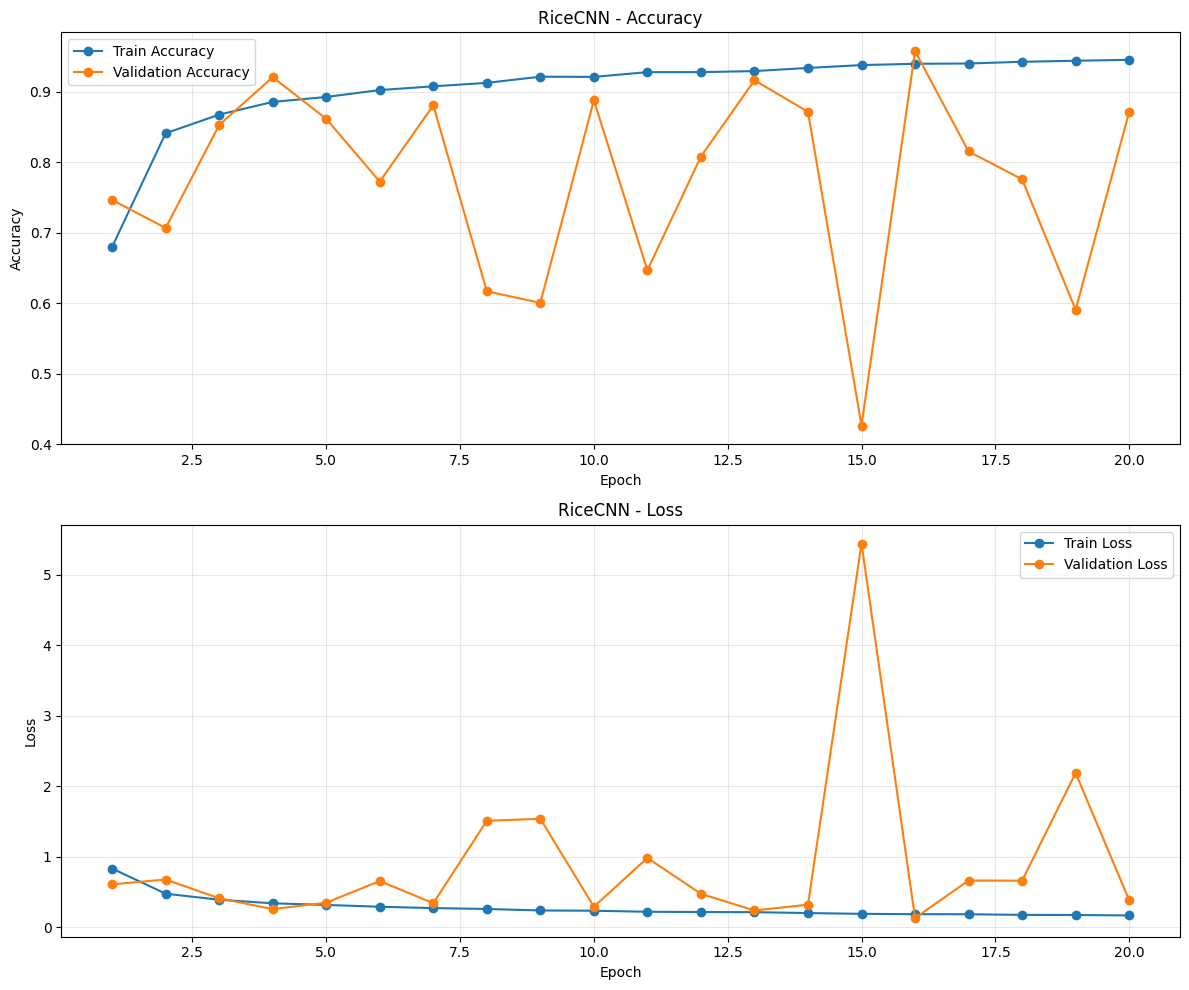

In [30]:
history = Rice_model.history
epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Accuracy
axes[0].plot(epochs, history["accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("RiceCNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history["loss"], marker="o", label="Train Loss")
axes[1].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("RiceCNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

html
<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h2 style="color: #174D35; margin-top: 0; font-weight: bold;">
    RiceCNN Accuracy Plot Interpretation
</h2>

The model demonstrates a consistent learning pattern on the training data, reaching **94.26% training accuracy** by the final epoch. However, the validation performance shows considerable fluctuations throughout training.

## Observations

- **Train Accuracy:** Starts at 69.58% and gradually increases to 94.26%, indicating that the model is progressively learning meaningful features from the training dataset.
- **Validation Accuracy:** Shows significant fluctuations across epochs, ranging from 40.04% to 95.66%.
- **Best Validation Performance:** The highest validation accuracy is achieved at Epoch 19 (95.66%), with a corresponding validation loss of 0.1303.
- **Severe Instability:** Epoch 12 shows a dramatic drop in validation accuracy to 40.04%, accompanied by an unusually high validation loss of 9.8903.
- **Final Epoch:** Validation accuracy decreases to 89.95%, while training accuracy continues to improve.

## Diagnosis

This behavior suggests **validation instability rather than clear evidence of classic overfitting**.

The large fluctuations in validation accuracy and loss may indicate unstable BatchNormalization statistics, particularly when the validation distribution or batch composition differs from the training batches.

However, the exact cause cannot be confirmed from training logs alone.

## Solution

To investigate and reduce the instability, we modify the `momentum` parameter of the BatchNormalization layers to `0.1`.

This adjustment allows the moving mean and variance to adapt more quickly to the current batch statistics.

We will compare the training and validation curves after this modification to determine whether it improves the consistency of validation performance.

</div>

In [31]:
def RiceCNN_V2():
    model = models.Sequential([
        layers.Input((Img_height, Img_width, 3)),

        # First convolutional block
        layers.Conv2D(filters=32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=0.1),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2, strides=2),

        # Classification
        layers.GlobalAveragePooling2D(),
        layers.Dense(units=64, activation="relu"),
        layers.Dropout(rate=0.3),
        layers.Dense(units=5, activation="softmax")

    ], name="RiceCNN_V2")
    
    # Compile model
    model.compile(optimizer="Adam", loss="categorical_crossentropy", metrics=["accuracy"])

    return model


model_RiceCNN_V2 = RiceCNN_V2()
model_RiceCNN_V2.summary()

Model: "RiceCNN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 250, 250, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 250, 250, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 250, 250, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 125, 125, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,461 (13.52 KB)

 Trainable params: 3,397 (13.27 KB)

 Non-trainable params: 64 (256.00 B)

In [32]:
start = time.perf_counter()

for i in range(20):
    images, labels = trainDataset[i]

elapsed = time.perf_counter() - start

print(f"Total loading time: {elapsed:.2f} seconds")
print(f"Average time per batch: {elapsed / 20:.3f} seconds")
print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")

Total loading time: 0.92 seconds
Average time per batch: 0.046 seconds
Images shape: (32, 250, 250, 3)
Labels shape: (32, 5)


In [33]:
Rice_model_V2 = model_RiceCNN_V2.fit(trainDataset, validation_data=valDataset, epochs=20)

Epoch 1/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 114s 68ms/step - accuracy: 0.7051 - loss: 0.7750 - val_accuracy: 0.8393 - val_loss: 0.4752
Epoch 2/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 110s 67ms/step - accuracy: 0.8251 - loss: 0.4908 - val_accuracy: 0.7991 - val_loss: 0.5192
Epoch 3/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 124s 75ms/step - accuracy: 0.8423 - loss: 0.4448 - val_accuracy: 0.8635 - val_loss: 0.3843
Epoch 4/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 108s 66ms/step - accuracy: 0.8589 - loss: 0.4068 - val_accuracy: 0.8885 - val_loss: 0.3422
Epoch 5/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 109s 66ms/step - accuracy: 0.8746 - loss: 0.3621 - val_accuracy: 0.8713 - val_loss: 0.3500
Epoch 6/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 112s 68ms/step - accuracy: 0.8936 - loss: 0.3154 - val_accuracy: 0.9136 - val_loss: 0.2546
Epoch 7/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 110s 67ms/step - accuracy: 0.9022 - loss: 0.2938 - val_accuracy: 0.8964 - val_loss: 0.2701
Epoch 8/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 110s 67ms/step - accuracy: 

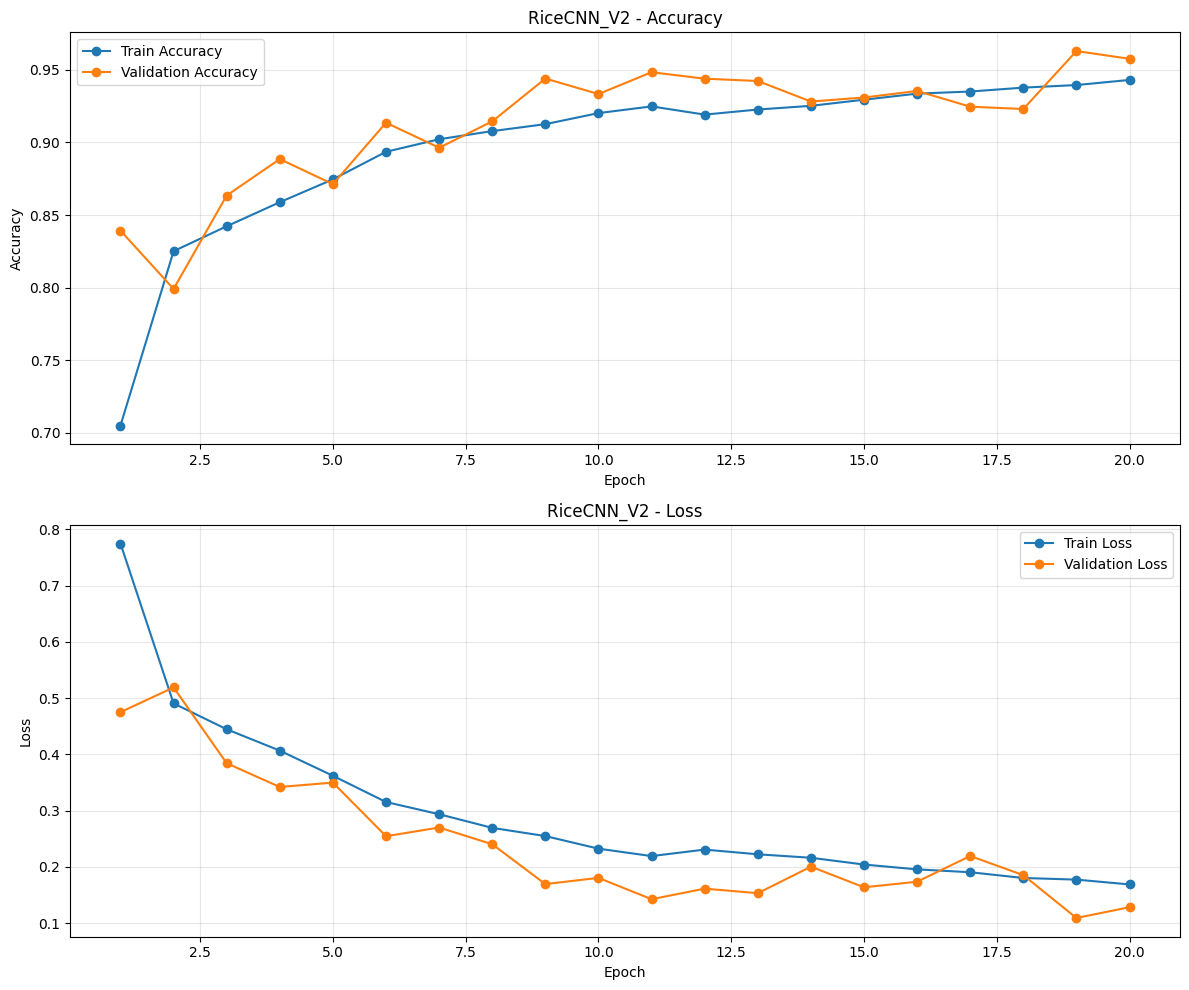

In [34]:
history = Rice_model_V2.history
epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Accuracy
axes[0].plot(epochs, history["accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("RiceCNN_V2 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history["loss"], marker="o", label="Train Loss")
axes[1].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("RiceCNN_V2 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h2 style="color: #174D35; margin-top: 0; font-weight: bold;">
    RiceCNN Accuracy Plot Interpretation
</h2>

The model demonstrates consistent learning progress after adjusting the `BatchNormalization` momentum to `0.1`.

Training and validation performance have improved, with significantly reduced validation fluctuations compared to the previous experiment.

## Observations

- **Train Accuracy:** Starts at 69.88% and gradually increases to 95.19%, indicating consistent learning throughout training.
- **Validation Accuracy:** Shows a much more stable upward trend compared to the previous experiment.
- **Best Validation Accuracy:** Reaches 96.76% at Epoch 18.
- **Best Validation Loss:** Reaches 0.0968 at Epoch 19.
- **Final Epoch:** Training accuracy reaches 95.19%, while validation accuracy remains at 95.60%.

## Diagnosis

The previous experiment showed severe validation instability, including a dramatic accuracy drop to 40.04% in Epoch 12.

After reducing the BatchNormalization momentum to `0.1`, validation performance became considerably more stable.

This suggests that updating the moving mean and variance more frequently may have contributed to improving validation consistency.

However, further experiments are needed to establish whether BatchNormalization momentum was the only factor responsible for this improvement.

## Conclusion

The modified model achieves:

- **Training Accuracy:** 95.19%
- **Best Validation Accuracy:** 96.76%
- **Best Validation Loss:** 0.0968

Overall, adjusting the BatchNormalization momentum has produced a promising improvement in both model performance and validation stability.

</div>


In [35]:
test_loss, test_accuracy = model_RiceCNN_V2.evaluate(testDataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

352/352 ━━━━━━━━━━━━━━━━━━━━ 680s 2s/step - accuracy: 0.9611 - loss: 0.1180
Test Loss: 0.1180
Test Accuracy: 0.9611


In [36]:
y_pred = model_RiceCNN_V2.predict(testDataset)

y_pred = np.argmax(y_pred, axis=1)
y_true = testDataset.classes

352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step


In [37]:
class_names = list(testDataset.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

     Arborio       0.98      0.92      0.95      2250
     Basmati       0.98      0.98      0.98      2250
      Ipsala       1.00      1.00      1.00      2250
     Jasmine       0.87      0.99      0.93      2250
   Karacadag       1.00      0.92      0.96      2250

    accuracy                           0.96     11250
   macro avg       0.96      0.96      0.96     11250
weighted avg       0.96      0.96      0.96     11250



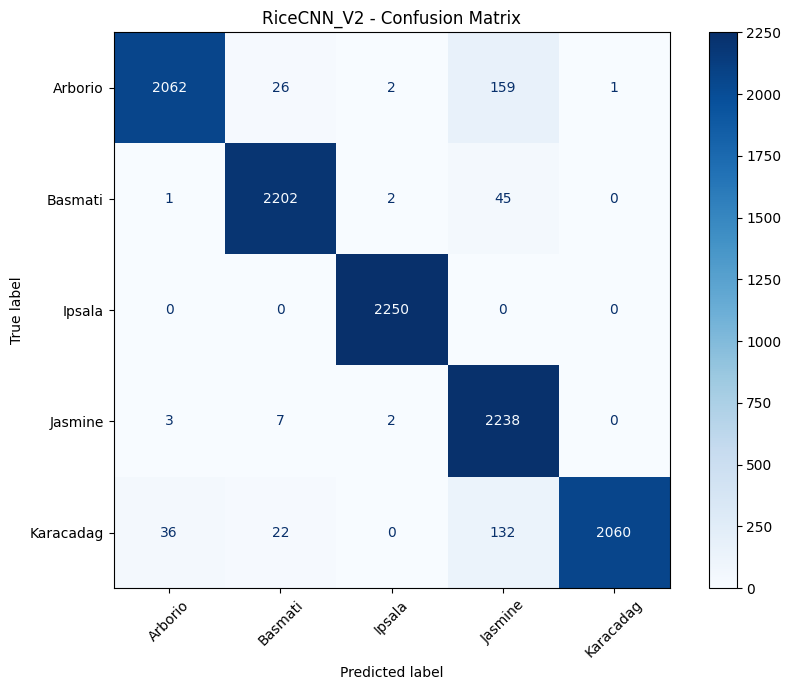

In [38]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap="Blues", ax=ax, xticks_rotation=45)
plt.title("RiceCNN_V2 - Confusion Matrix")
plt.tight_layout()
plt.show()

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h2 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Improving Classification Between Arborio and Jasmine
</h2>
<p>
    
Although the CNN model achieves a relatively high overall test accuracy of 95.81%, the classification report reveals that its performance is not equally strong across all rice categories.

In particular, the model has difficulty distinguishing between Arborio and Jasmine rice. The recall for Arborio is 87%, while the precision for Jasmine is also 87%. Furthermore, 191 Arborio samples are incorrectly classified as Jasmine.

This suggests that the model may not be learning sufficiently discriminative visual features to distinguish these two classes.

To investigate this issue, we will first examine representative images from both categories. Then, as an experimental improvement, we will add an additional convolutional layer to the CNN architecture to help the model learn more detailed visual features.

Our objective is to improve the model's ability to distinguish between Arborio and Jasmine without negatively affecting its performance on the other classes.

Note: The effectiveness of this architectural modification will be evaluated through a comparison of the new model's validation and test performance.
</p>
</div>

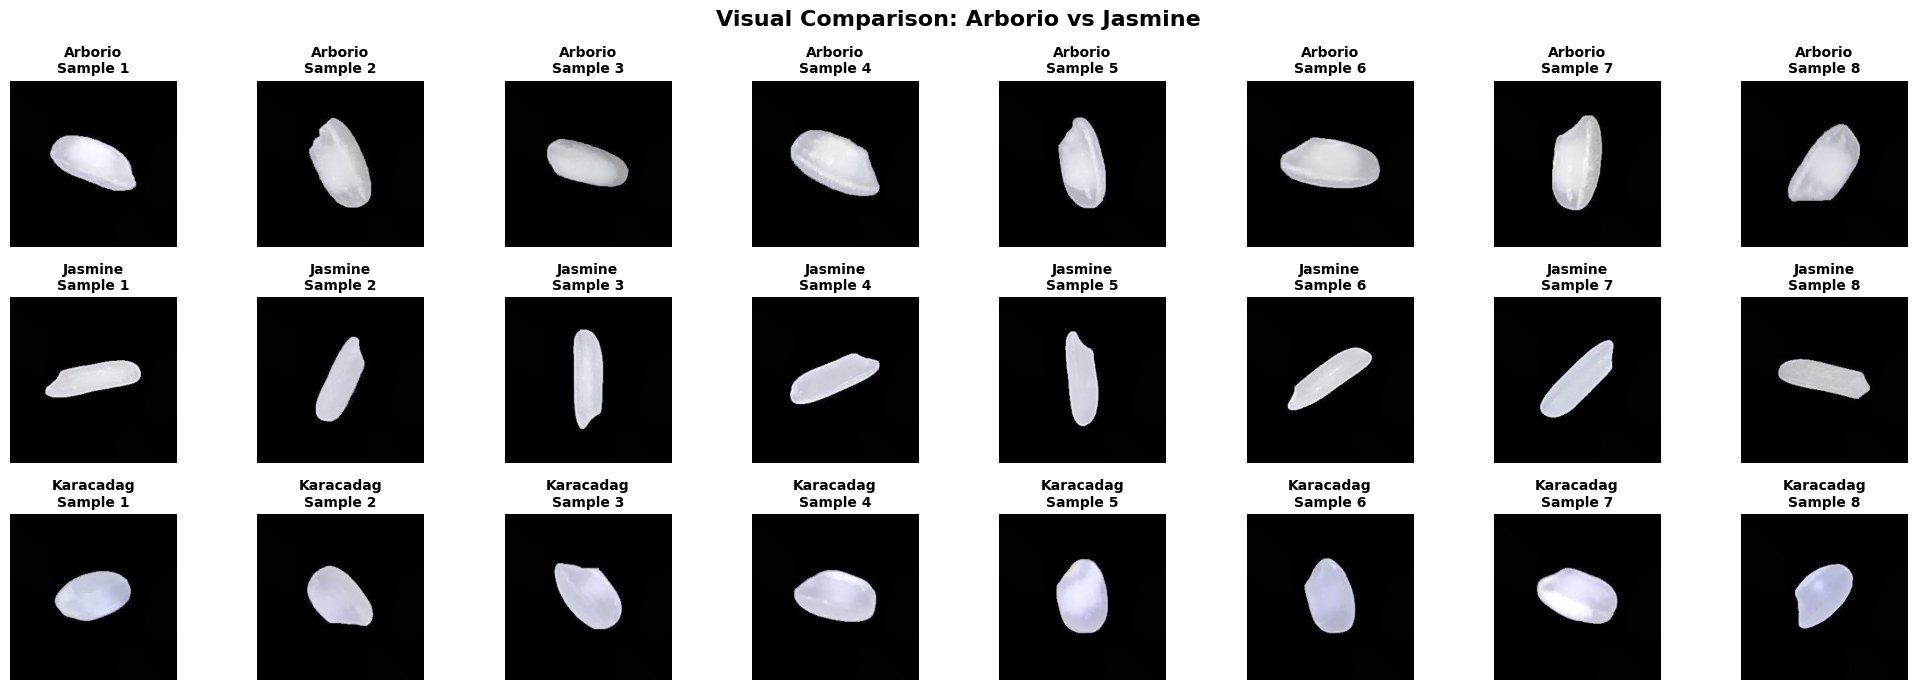

In [44]:
dataset_path = "/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset"

target_classes = ["Arborio", "Jasmine", "Karacadag"]

random.seed(42)

fig, axes = plt.subplots(3, 8, figsize=(20, 7))

for row, class_name in enumerate(target_classes):

    class_path = os.path.join(dataset_path, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected_images = random.sample(image_files, 8)

    for col, image_name in enumerate(selected_images):

        img_path = os.path.join(class_path, image_name)
        img = load_img(img_path)

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

        axes[row, col].set_title(
            f"{class_name}\nSample {col + 1}",
            fontsize=10,
            fontweight="bold"
        )

plt.suptitle(
    "Visual Comparison: Arborio vs Jasmine",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [45]:
def RiceNet():
    model = models.Sequential([
        layers.Input((Img_height, Img_width, 3)),

        # First convolutional block
        layers.Conv2D(filters=32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=0.1),
        layers.Activation("relu"),

        # Second convolutional layer
        layers.Conv2D(filters=64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=0.1),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2, strides=2),

        # Classification
        layers.GlobalAveragePooling2D(),
        layers.Dense(units=64, activation="relu"),
        layers.Dropout(rate=0.3),
        layers.Dense(units=5, activation="softmax")

    ], name="RiceNet")

    # Compile model
    model.compile(optimizer="Adam", loss="categorical_crossentropy", metrics=["accuracy"])

    return model


model_RiceNet = RiceNet()
model_RiceNet.summary()

Model: "RiceNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 250, 250, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 250, 250, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 250, 250, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 250, 250, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 250, 250, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 250, 250, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 125, 125, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,261 (94.77 KB)

 Trainable params: 24,069 (94.02 KB)

 Non-trainable params: 192 (768.00 B)

In [46]:
%%time
model_RiceNet_model = model_RiceNet.fit(trainDataset, validation_data=valDataset, epochs=20)

Epoch 1/20
  45/1641 ━━━━━━━━━━━━━━━━━━━━ 3:44 141ms/step - accuracy: 0.3214 - loss: 1.4913

2026-11-08 16:43:02.885606: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-08 16:43:03.196838: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1641/1641 ━━━━━━━━━━━━━━━━━━━━ 269s 157ms/step - accuracy: 0.8350 - loss: 0.4847 - val_accuracy: 0.9236 - val_loss: 0.2336
Epoch 2/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 249s 151ms/step - accuracy: 0.9368 - loss: 0.2032 - val_accuracy: 0.9057 - val_loss: 0.2425
Epoch 3/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 248s 151ms/step - accuracy: 0.9530 - loss: 0.1476 - val_accuracy: 0.9550 - val_loss: 0.1359
Epoch 4/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 247s 150ms/step - accuracy: 0.9643 - loss: 0.1106 - val_accuracy: 0.9830 - val_loss: 0.0541
Epoch 5/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 246s 150ms/step - accuracy: 0.9656 - loss: 0.1040 - val_accuracy: 0.9820 - val_loss: 0.0548
Epoch 6/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 246s 150ms/step - accuracy: 0.9735 - loss: 0.0819 - val_accuracy: 0.9672 - val_loss: 0.0845
Epoch 7/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 246s 150ms/step - accuracy: 0.9727 - loss: 0.0815 - val_accuracy: 0.9689 - val_loss: 0.0778
Epoch 8/20
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 245s 149ms/step - accuracy: 0.9

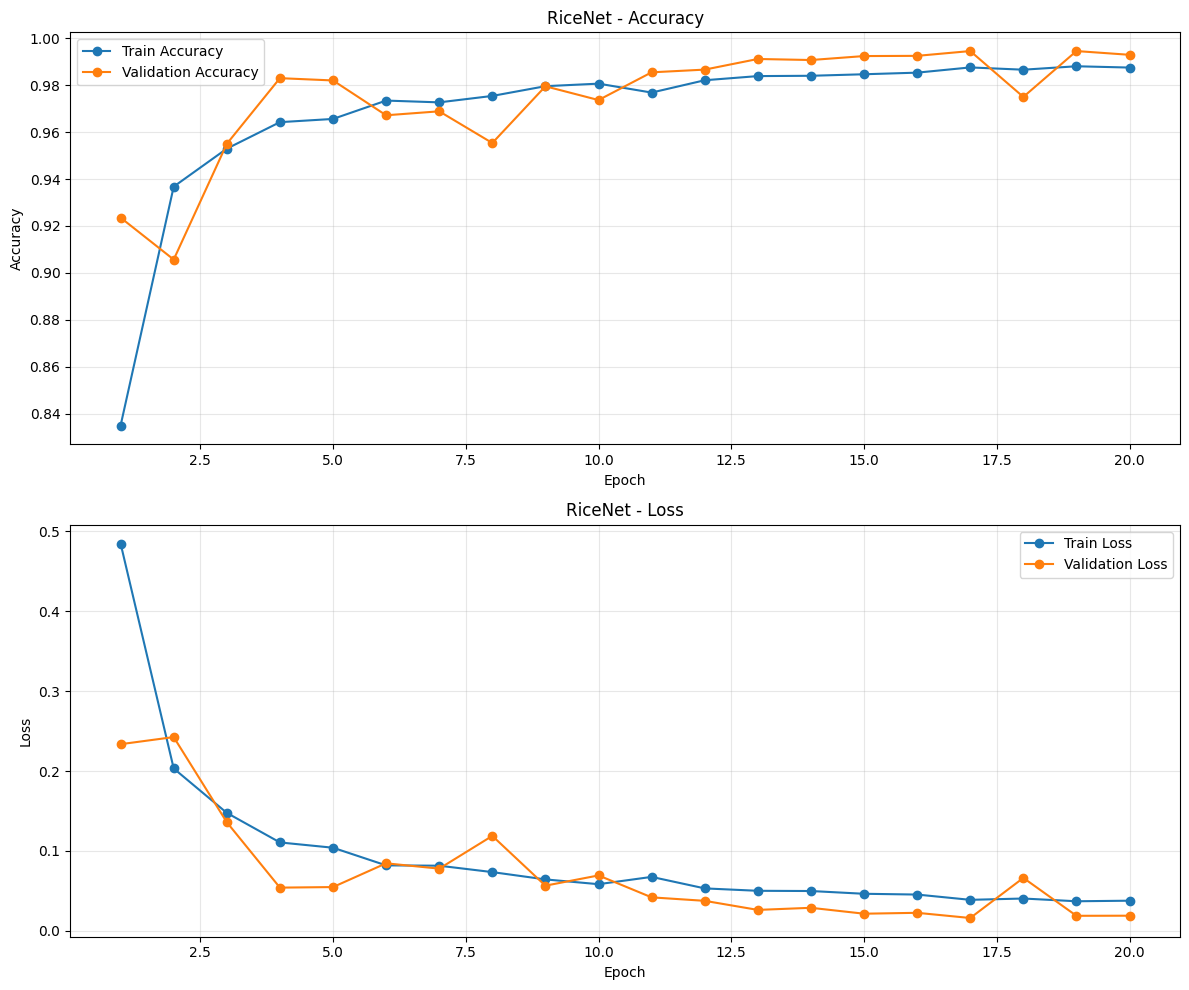

In [48]:
history = model_RiceNet_model.history
epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Accuracy
axes[0].plot(epochs, history["accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("RiceNet - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history["loss"], marker="o", label="Train Loss")
axes[1].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("RiceNet - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [49]:
test_loss, test_accuracy = model_RiceNet.evaluate(
    testDataset,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.9948 - loss: 0.0164
Test Loss: 0.0164
Test Accuracy: 0.9948


352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 53ms/step
              precision    recall  f1-score   support

     Arborio     0.9969    0.9898    0.9933      2250
     Basmati     0.9996    0.9880    0.9937      2250
      Ipsala     1.0000    1.0000    1.0000      2250
     Jasmine     0.9808    0.9987    0.9896      2250
   Karacadag     0.9973    0.9978    0.9976      2250

    accuracy                         0.9948     11250
   macro avg     0.9949    0.9948    0.9949     11250
weighted avg     0.9949    0.9948    0.9949     11250



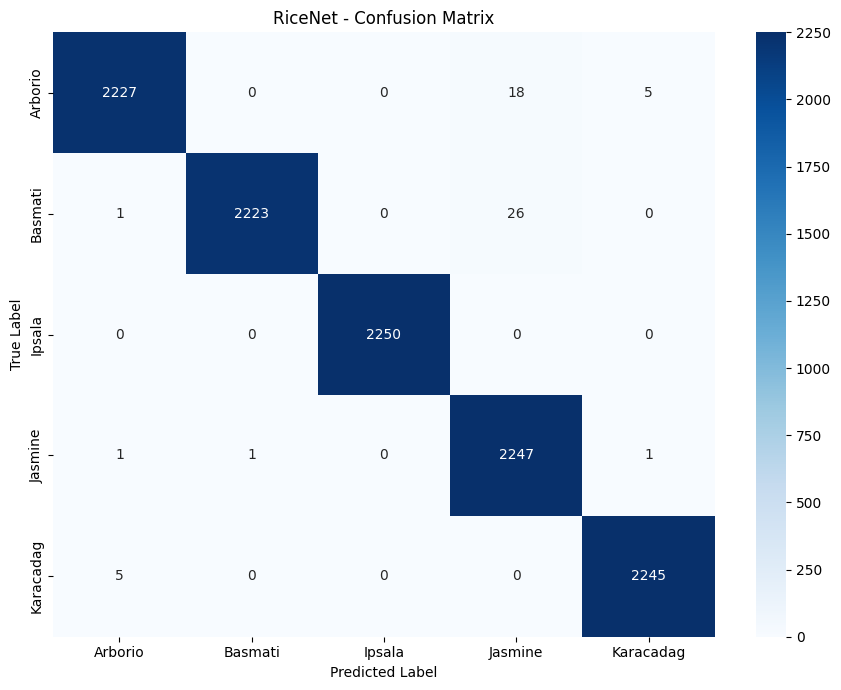

In [50]:
# Predict probabilities
y_proba = model_RiceNet.predict(testDataset, verbose=1)

# Predicted and actual labels
y_pred = np.argmax(y_proba, axis=1)
y_true = testDataset.classes

# Class names
class_names = list(testDataset.class_indices.keys())

# Classification Report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("RiceNet - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h2 style="color: #174D35; margin-top: 0; font-weight: bold;">
    RiceNet – Improved Classification Performance
</h2>
<p>
    
After adding a second convolutional layer with 64 filters, the new architecture achieved significantly better classification performance.

The test accuracy increased from **96.11% to 99.48%**, while the test loss decreased from 0.1185 to 0.0164.

The most notable improvement was observed in the classification of Arborio and Jasmine rice:

- Arborio Recall improved from 87% to 98.98%.
- Jasmine Precision improved from 87% to 98.08%.

These results suggest that the additional convolutional layer helped the model learn more discriminative visual features, improving its ability to distinguish between visually similar rice varieties.

Overall, RiceNet demonstrated substantially better performance across all five classes compared with the previous architecture.
</p>
</div>

In [80]:
def test_random_images(model, dataset, class_names, num_images=12):

    # Select random images
    num_images = min(num_images, len(dataset.filepaths))
    random_indices = random.sample(range(len(dataset.filepaths)), num_images)

    # Load and preprocess images
    images = []
    actual_classes = []

    for index in random_indices:

        image_path = dataset.filepaths[index]

        img = load_img(image_path, target_size=(Img_height, Img_width))

        img_array = img_to_array(img) / 255.0

        images.append(img_array)
        actual_classes.append(os.path.basename(os.path.dirname(image_path)))

    # Predict all images together
    images = np.array(images)
    predictions = model.predict(images, verbose=0)

    # Visualization
    n_cols = 4
    n_rows = math.ceil(num_images / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4), squeeze=False)

    axes = axes.flatten()

    for i in range(num_images):

        predicted_index = np.argmax(predictions[i])
        predicted_class = class_names[predicted_index]
        confidence = predictions[i][predicted_index] * 100

        actual_class = actual_classes[i]

        is_correct = predicted_class == actual_class

        axes[i].imshow(images[i])
        axes[i].axis("off")

        axes[i].set_title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2f}%",
            color="green" if is_correct else "red",
            fontsize=10,
            fontweight="bold"
        )

    # Hide empty axes
    for i in range(num_images, len(axes)):
        axes[i].axis("off")

    plt.suptitle("RiceNet - Random Image Predictions", fontsize=16, fontweight="bold")

    plt.tight_layout()
    plt.show()

    # Summary
    correct = sum(np.argmax(predictions[i]) == class_names.index(actual_classes[i]) for i in range(num_images))

    print(f"Total Images : {num_images}")
    print(f"Correct      : {correct}")
    print(f"Incorrect    : {num_images - correct}")
    print(f"Accuracy     : {correct / num_images * 100:.2f}%")

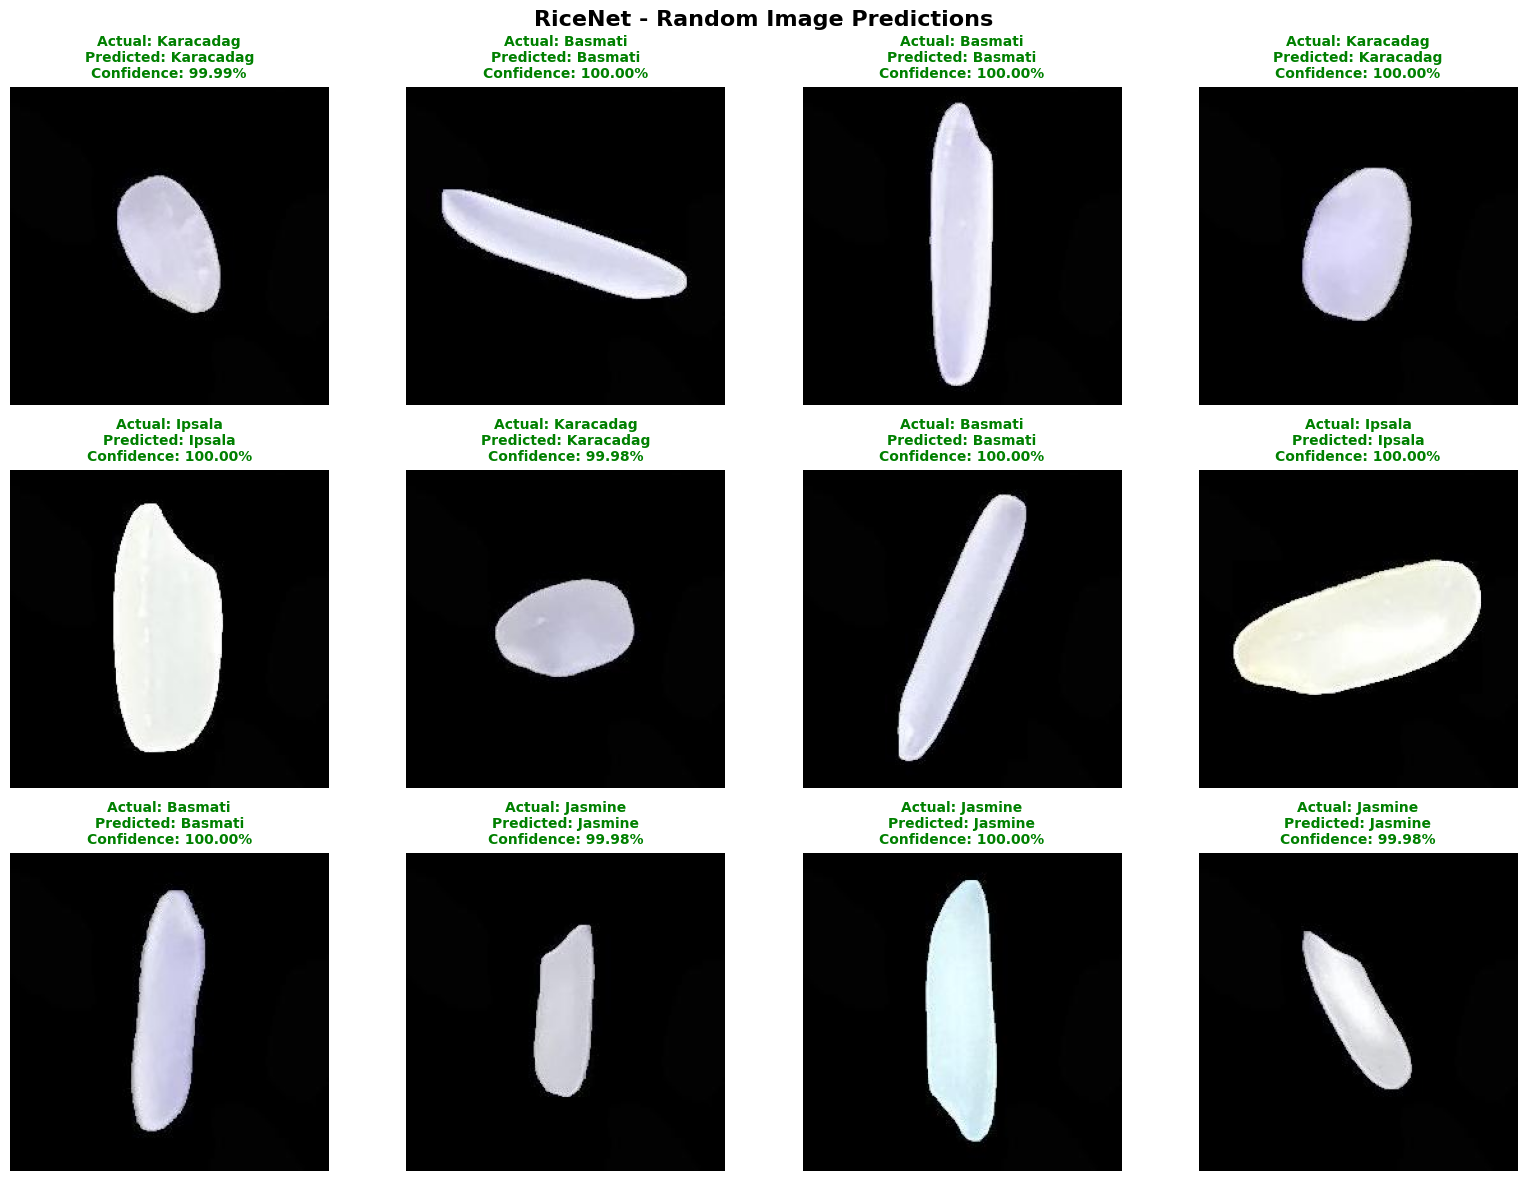

Total Images : 12
Correct      : 12
Incorrect    : 0
Accuracy     : 100.00%


In [81]:
image_path = testDataset.filepaths[random_index]

test_random_images(model=model_RiceNet, dataset=testDataset, class_names=class_names, num_images=12)

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Thank You :)
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Thank you for taking the time to explore this project.
        <br>
        See you in the next project!
    </p>
</div>
